# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  312.3  steps_to_475 147774  final  500.0  time  78.3 s
seed 1: auc  244.2  steps_to_475  95166  final  294.8  time  72.6 s
seed 2: auc  329.1  steps_to_475  76370  final  495.1  time  67.9 s
seed 3: auc  340.3  steps_to_475  69435  final  453.4  time  68.3 s
seed 4: auc  361.6  steps_to_475  99675  final  500.0  time  68.0 s
seed 0: auc  252.0  steps_to_475  68297  final  170.9  time  67.5 s
seed 1: auc  379.3  steps_to_475  79270  final  500.0  time  68.2 s
seed 2: auc  311.2  steps_to_475  65676  final  475.6  time  70.6 s
seed 3: auc  361.7  steps_to_475  57064  final  500.0  time  72.9 s
seed 4: auc  364.4  steps_to_475  54662  final  500.0  time  71.3 s
seed 0: auc  287.8  steps_to_475 165270  final  500.0  time  70.8 s
seed 1: auc  300.6  steps_to_475 113729  final  495.8  time  73.4 s
seed 2: auc  344.6  steps_to_475  85506  final  500.0  time  72.0 s
seed 3: auc  337.0  steps_to_475  93652  final  495.9  time  71.7 s
seed 4: auc  328.9  steps_to_475  73589  final  

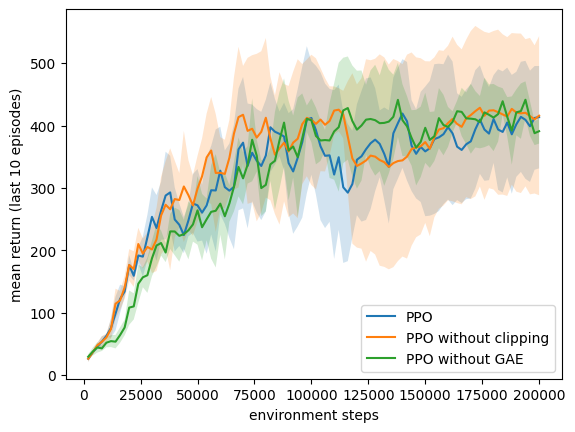

In [6]:
all_runs = {"PPO": run_seeds()}
# TODO: train the two changed versions
all_runs["PPO without clipping"] = run_seeds({"clip_coef": 1e9})
all_runs["PPO without GAE"] = run_seeds({"gae_lambda": 1.0})
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [7]:
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    # TODO: your method
    raise NotImplementedError

# (b) LLM checkpoint evaluation

Run the four code cells below on a Colab T4 after part (a) finishes and its outputs are saved. Run only part (b) after changing runtime.

Compare the four checkpoints on GSM8K (math reasoning) and TruthfulQA MC1 (truthfulness), using the same first 200 questions per task and seed = 0. Keep the built-in task prompts identical across checkpoints. GSM8K uses its default 5-shot context. TruthfulQA MC1 uses its built-in fixed demonstration prompt; num_fewshot remains 0. SFT/DPO/Instruct use their own chat templates; Base uses plain text.

GSM8K is scored by exact match with strict and flexible answer extraction. Generation is greedy, with a 2,048-token limit. TruthfulQA MC1 is scored by the log-likelihood of candidate answers, without sampling. Two additional free-text TruthfulQA answers per checkpoint use the exact scored prompts, the same greedy settings, and stop at a new Q: line; these examples are qualitative and do not contribute to the MC1 score.

The final cell checks unique question IDs and question hashes across checkpoints, prints a results table and two questions per task with all four models directly in the notebook. Full results and examples are saved in q3_b_gsm8k_truthfulqa_mc1_results. The earlier Evaluation cell remains for CartPole in part (a).

Sources: [GSM8K task](https://github.com/EleutherAI/lm-evaluation-harness/blob/v0.4.9.2/lm_eval/tasks/gsm8k/gsm8k.yaml), [TruthfulQA MC1 task](https://github.com/EleutherAI/lm-evaluation-harness/blob/v0.4.9.2/lm_eval/tasks/truthfulqa/truthfulqa_mc1.yaml).


In [ ]:
%pip install -q "lm_eval==0.4.9.2" "transformers==4.57.1" "datasets==4.3.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 wh

In [ ]:
import gc
import json
from pathlib import Path
import torch
from lm_eval import simple_evaluate
from lm_eval.api.instance import Instance
from lm_eval.models.huggingface import HFLM
from lm_eval.utils import handle_non_serializable, make_table

print(torch.cuda.is_available())

seed = 0
llm_tasks = ["gsm8k", "truthfulqa_mc1"]
llm_limit = 200
llm_gen_kwargs = {"do_sample": False, "temperature": 0.0, "max_gen_toks": 2048}


True


In [ ]:
model = {
    "Base": "allenai/OLMo-2-0425-1B",
    "SFT": "allenai/OLMo-2-0425-1B-SFT",
    "DPO": "allenai/OLMo-2-0425-1B-DPO",
    "RLVR": "allenai/OLMo-2-0425-1B-Instruct",
}
llm_results = {}
llm_output_dir = Path("q3_b_gsm8k_truthfulqa_mc1_results")
llm_output_dir.mkdir(exist_ok=True)

def samples_by_id(result, task):
    samples = {}
    for sample in result["samples"][task]:
        samples.setdefault(sample["doc_id"], sample)
    return dict(sorted(samples.items()))

def save_llm_result(stage, result):
    with (llm_output_dir / f"{stage}.json").open("w") as f:
        json.dump(result, f, default=handle_non_serializable, ensure_ascii=False, indent=2)

for stage, model_id in model.items():
    print("Evaluating", stage, model_id)
    lm = HFLM(pretrained=model_id, dtype="float16", batch_size=4, device="cuda")
    result = simple_evaluate(
          model=lm, tasks=llm_tasks, limit=llm_limit, apply_chat_template=(stage != "Base"),
          gen_kwargs=llm_gen_kwargs.copy(), log_samples=True, bootstrap_iters=0,
          random_seed=seed, numpy_random_seed=seed,torch_random_seed=seed, fewshot_random_seed=seed,
    )
    result["checkpoint_id"] = model_id
    llm_results[stage] = result
    save_llm_result(stage, result)
    print(make_table(result))
    examples = list(samples_by_id(result, "truthfulqa_mc1").values())[:2]
    example_gen_kwargs = {**llm_gen_kwargs, "until": ["\nQ:"]}
    requests = [
        Instance(request_type="generate_until", doc=sample["doc"], arguments=(sample["arguments"][0][0], example_gen_kwargs.copy()),
                 idx=0, metadata=("truthfulqa_mc1_examples", sample["doc_id"], 1),
        )
        for sample in examples]
    generated = lm.generate_until(requests)
    result["truthfulqa_qualitative_examples"] = [
        {"doc_id": sample["doc_id"], "question": sample["doc"]["question"], "model_input": sample["arguments"][0][0],
         "generation_kwargs": example_gen_kwargs.copy(), "output": output,}
          for sample, output in zip(examples, generated)]
    save_llm_result(stage, result)
    del lm
    gc.collect()
    torch.cuda.empty_cache()


Evaluating Base allenai/OLMo-2-0425-1B


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (53 outputs left out)

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

Running generate_until requests: 100%|██████████| 200/200 [20:04<00:00,  6.02s/it]


|    Tasks     |Version|     Filter     |n-shot|  Metric   |   |Value|   |Stderr|
|--------------|------:|----------------|-----:|-----------|---|----:|---|------|
|gsm8k         |      3|flexible-extract|     5|exact_match|↑  |0.690|±  |   N/A|
|              |       |strict-match    |     5|exact_match|↑  |0.565|±  |   N/A|
|truthfulqa_mc1|      2|none            |     0|acc        |↑  |0.310|±  |   N/A|



Running generate_until requests: 100%|██████████| 2/2 [00:01<00:00,  1.67it/s]


In [ ]:
# (b) 3. Show the results and example answers directly in the notebook.
assert set(llm_results) == set(model)
sample_maps = {
    stage: {task: samples_by_id(result, task) for task in llm_tasks}
    for stage, result in llm_results.items()
}
for task in llm_tasks:
    expected = sample_maps["Base"][task]
    assert len(expected) == llm_limit
    for stage in model:
        current = sample_maps[stage][task]
        assert current.keys() == expected.keys()
        assert all(current[i]["doc_hash"] == expected[i]["doc_hash"] for i in expected)

for stage, result in llm_results.items():
    gsm = result["results"]["gsm8k"]
    truthful = result["results"]["truthfulqa_mc1"]
    print(f"{stage}: {gsm['exact_match,flexible-extract']:.2f}, GSM8K strict: {gsm['exact_match,strict-match']:.2f}, TruthfulQA MC1: {truthful['acc,none']:.2f}")

qualitative = {
    stage: {sample["doc_id"]: sample for sample in result["truthfulqa_qualitative_examples"]}
    for stage, result in llm_results.items()
}
for task in llm_tasks:
    for doc_id in list(sample_maps["Base"][task])[:2]:
        doc = sample_maps["Base"][task][doc_id]["doc"]
        print(task, "question", doc_id)
        print("Question:", doc["question"])
        if task == "gsm8k":
            reference = doc["answer"]
        else:
            targets = doc["mc1_targets"]
            reference = targets["choices"][targets["labels"].index(1)]
        print("Reference:", reference)
        for stage in model:
            sample = sample_maps[stage][task][doc_id]
            if task == "gsm8k":
                output = sample["resps"][0][0]
                label = "generated answer"
            else:
                best = max(range(len(sample["resps"])), key=lambda j: sample["resps"][j][0][0])
                print("\n" + stage + " MC1 selected answer:", sample["doc"]["mc1_targets"]["choices"][best])
                print("MC1 correct:", bool(sample["acc"]))
                output = qualitative[stage][doc_id]["output"]
                label = "qualitative answer"
            print("\n" + stage + " " + label + ":\n" + output)


Base: 0.35, GSM8K strict: 0.35, TruthfulQA MC1: 0.22
SFT: 0.34, GSM8K strict: 0.24, TruthfulQA MC1: 0.26
DPO: 0.47, GSM8K strict: 0.40, TruthfulQA MC1: 0.28
RLVR: 0.69, GSM8K strict: 0.56, TruthfulQA MC1: 0.31
gsm8k question 0
Question: Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?
Reference: Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eggs a day.
She makes 9 * 2 = $<<9*2=18>>18 every day at the farmer’s market.
#### 18

Base generated answer:
 Janet eats 3 eggs per day, so she has 16 - 3 = <<16-3=13>>13 eggs left.
She sells the remainder at the farmers' market for $2 per egg, so she makes 13 * 2 = $<<13*2=26>>26 dollars every day.
#### 26

SFT generated answer:
She eats 3 eggs for breakfast and bakes 4 muffins so she uses 3 + 4 = <<3+4=7>>7 eggs per day.